# 🚀 Practice Day 32

**📅 Date:** 2026-10-12   
📁 Category: Phase 1 · 시각화 기초 (Round 3/5)

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Practice core chart types (bar, line, and pie) to compare ticket types and show the seasonal pattern across a year
  (막대·선·파이 그래프 등 기본 차트 유형 연습 — 티켓 유형 비교와 연중 계절성 표현)
- Find which ticket type drives the most revenue and when the park's busiest months are
  (어떤 티켓 유형이 매출을 가장 많이 견인하는지, 놀이공원이 가장 붐비는 달은 언제인지 파악하기)

---
# 📂 Dataset

**Dataset Name:** Starlight Adventure Park — 티켓 유형별 월간 판매 (2024) / Starlight Adventure Park — Monthly Ticket Sales by Type (2024)

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** 2024 monthly ticket sales for a theme park, covering 5 ticket types (Adult, Child, Senior, Annual Pass, Group) — 60 rows total (5 types × 12 months), single table. Revenue is in USD. Sales spike clearly in the summer peak season (June-August) and in December. Clean — no missing values or duplicates.
(테마파크의 2024년 1~12월 티켓 판매 데이터로, 5개 티켓 유형(Adult/Child/Senior/Annual Pass/Group)별 월간 판매량과 매출을 담고 있습니다(단일 테이블, 60행 = 5유형×12개월, 매출은 USD). 여름 성수기(6~8월)와 12월 연말에 판매량이 뚜렷하게 높아지며, 결측치·중복 없이 깨끗합니다.)

## Dataset Preview

In [54]:
# Dataset Preview
import pandas as pd
import numpy as np

np.random.seed(42)
rng = np.random.default_rng(42)

# --- Generate monthly ticket sales by type for a theme park ---
ticket_types = ['Adult', 'Child', 'Senior', 'Annual Pass', 'Group']
avg_price = {'Adult': 55, 'Child': 40, 'Senior': 35, 'Annual Pass': 180, 'Group': 32}  # USD per ticket
base_tickets = {'Adult': 3200, 'Child': 2200, 'Senior': 900, 'Annual Pass': 150, 'Group': 1400}

months = pd.date_range('2024-01-01', periods=12, freq='MS')
# Seasonal index per month (Jan..Dec): summer peak + December holiday bump
seasonal = [0.65, 0.6, 0.75, 0.85, 0.95, 1.35, 1.55, 1.5, 0.9, 0.8, 0.85, 1.25]

rows = []
for t in ticket_types:
    for i, m in enumerate(months):
        noise = rng.normal(1.0, 0.06)
        tickets = base_tickets[t] * seasonal[i] * noise
        tickets = max(1, int(round(tickets)))
        revenue = tickets * avg_price[t]
        rows.append({'month': m, 'ticket_type': t, 'tickets_sold': tickets, 'revenue': revenue})

df = pd.DataFrame(rows).sort_values(['month', 'ticket_type']).reset_index(drop=True)

df.head(10)


,month,ticket_type,tickets_sold,revenue
0,2024-01-01,Adult,2118,116490
1,2024-01-01,Annual Pass,97,17460
2,2024-01-01,Child,1436,57440
3,2024-01-01,Group,947,30304
4,2024-01-01,Senior,570,19950
5,2024-02-01,Adult,1800,99000
6,2024-02-01,Annual Pass,85,15300
7,2024-02-01,Child,1409,56360
8,2024-02-01,Group,843,26976
9,2024-02-01,Senior,529,18515


## Dataset Information

In [55]:
# Dataset Information
df.info()
print("\nShape:", df.shape)
df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   month         60 non-null     datetime64[us]
 1   ticket_type   60 non-null     str           
 2   tickets_sold  60 non-null     int64         
 3   revenue       60 non-null     int64         
dtypes: datetime64[us](1), int64(2), str(1)
memory usage: 2.0 KB

Shape: (60, 4)


,month,ticket_type,tickets_sold,revenue
count,60,60,60.000000,60.000000
unique,NaN,5,NaN,NaN
top,NaN,Adult,NaN,NaN
freq,NaN,12,NaN,NaN
mean,2024-06-16 08:00:00,NaN,1568.900000,73339.716667
min,2024-01-01 00:00:00,NaN,85.000000,15300.000000
25%,2024-03-24 06:00:00,NaN,694.000000,27685.000000
50%,2024-06-16 00:00:00,NaN,1281.500000,44852.500000
75%,2024-09-08 12:00:00,NaN,2122.500000,101500.000000
max,2024-12-01 00:00:00,NaN,4998.000000,274890.000000


---
# ❓ Business Questions

1. **(Analysis)** Which ticket type generates the most total revenue, and which the least?
   (가장 매출이 높은/낮은 티켓 유형은?)
2. **(Analysis)** How does total monthly ticket volume (all types combined) change across the year?
   (전체 티켓 판매량은 월별로 어떻게 변화하는가?)
3. **(Analysis)** What percentage of total annual revenue does each ticket type contribute?
   (티켓 유형별 연간 매출 비중은 각각 몇 %인가?)
4. **(Visualization)** Compare total revenue across all 5 ticket types.
   (5개 티켓 유형의 총매출을 비교하면?)
5. **(Visualization)** Show how total monthly ticket sales move across the year.
   (연중 월별 총 판매량은 어떻게 움직이는가?)

---
# 🔍 Data Cleaning Check


In [56]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
month           0
ticket_type     0
tickets_sold    0
revenue         0
dtype: int64

Duplicate rows: 0

Dtypes
month           datetime64[us]
ticket_type                str
tickets_sold             int64
revenue                  int64
dtype: object

Column names
['month', 'ticket_type', 'tickets_sold', 'revenue']

Text columns — unique counts
ticket_type    5
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** Which ticket type generates the most total revenue, and which the least? (가장 매출이 높은/낮은 티켓 유형은?)

**Result:** Adult is highest at **$2,091,650**. Annual Pass is lowest at **$326,160**.  
(가장 높은 유형은 Adult $2,091,650, 가장 낮은 유형은 Annual Pass $326,160)

**Insight:** Adult is **$1,765,490** above Annual Pass and **$1,031,330** above the second place, Child (**$1,060,320**).  
(Adult는 Annual Pass보다 $1,765,490, 2위 Child($1,060,320)보다 $1,031,330 높음)


In [57]:
# Question 1: total revenue by ticket_type (highest / lowest)

df.groupby('ticket_type')['revenue'].sum().sort_values(ascending=False)

ticket_type
Adult          2091650
Child          1060320
Group           535328
Senior          386925
Annual Pass     326160
Name: revenue, dtype: int64

## Question 2

**Question:** How does total monthly ticket volume (all types combined) change across the year? (월별 총 판매량 변화는?)

**Result:** Volume starts at **5,168** in January, dips to **4,666** in February, and peaks at **12,494** in July. It falls to **6,144** in October and rises to **10,155** in December.  
(1월 5,168로 시작해 2월 4,666으로 내려가고 7월 12,494에서 최고. 10월 6,144까지 떨어졌다가 12월 10,155로 오름)

**Insight:** July is **7,828** above February. June to August add up to **34,148** tickets, and December (**10,155**) is higher than June (**10,090**).  
(7월은 2월보다 7,828 많음. 6~8월 합계는 34,148장이고, 12월(10,155)이 6월(10,090)보다 높음)


month
2024-01-01     5168
2024-02-01     4666
2024-03-01     6076
2024-04-01     6797
2024-05-01     7059
2024-06-01    10090
2024-07-01    12494
2024-08-01    11564
2024-09-01     6995
2024-10-01     6144
2024-11-01     6926
2024-12-01    10155
Name: tickets_sold, dtype: int64

<Axes: xlabel='month'>

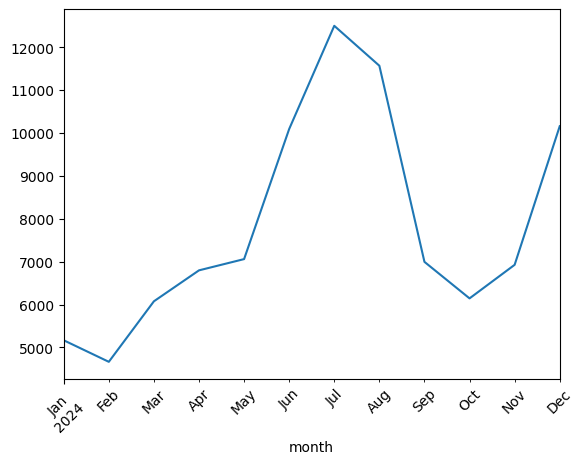

In [58]:
# Question 2: total monthly ticket volume (all types combined) across the year
monthly_tickets = df.groupby('month')['tickets_sold'].sum()
display(monthly_tickets)
monthly_tickets.plot(kind='line', rot=45)

## Question 3

**Question:** What percentage of total annual revenue does each ticket type contribute? (유형별 연간 매출 비중은?)

**Result:** Adult **47.5%**, Child **24.1%**, Group **12.2%**, Senior **8.8%**, Annual Pass **7.4%**.  
(Adult 47.5%, Child 24.1%, Group 12.2%, Senior 8.8%, Annual Pass 7.4%)

**Insight:** Adult and Child together are **71.6%** of annual revenue. The other three types share the remaining **28.4%**.  
(Adult와 Child를 합치면 연간 매출의 71.6%. 나머지 세 유형이 28.4%를 나눠 가짐)


ticket_type
Adult          47.533362
Child          24.096084
Group          12.165487
Senior          8.792985
Annual Pass     7.412082
Name: revenue, dtype: float64

<Axes: >

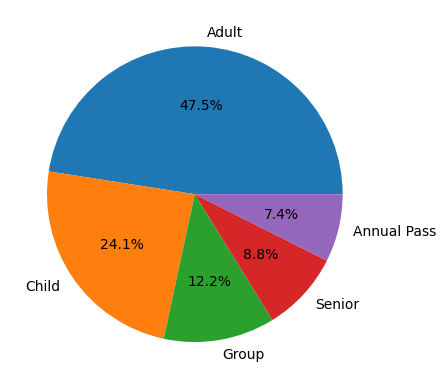

In [59]:
# Question 3: each ticket type's % share of total annual revenue
ratios = (df.groupby('ticket_type')['revenue'].sum() / df['revenue'].sum() * 100).sort_values(ascending=False)
display(ratios)
ratios.plot(kind='pie', autopct='%1.1f%%')

---
# 📈 Visualization

**Chart 1:** Bar chart — total revenue by ticket type (막대그래프: 티켓 유형별 총매출)

*Interpretation:* The bars fall from Adult (**$2,091,650**) to Child (**$1,060,320**), Group (**$535,328**), Senior (**$386,925**), and Annual Pass (**$326,160**). Adult is about twice as tall as Child.  
(막대는 Adult $2,091,650, Child $1,060,320, Group $535,328, Senior $386,925, Annual Pass $326,160 순으로 낮아짐. Adult는 Child의 약 2배 높이)

---

**Chart 2:** Line chart — total monthly ticket sales trend (선그래프: 월별 총 판매량 추이)

*Interpretation:* The line dips to **4,666** in February, climbs to a peak of **12,494** in July, and falls to **6,995** in September. It rises again to **10,155** in December.  
(선은 2월 4,666으로 내려갔다가 7월 12,494로 최고점에 오르고, 9월 6,995로 떨어짐. 12월에 다시 10,155로 오름)


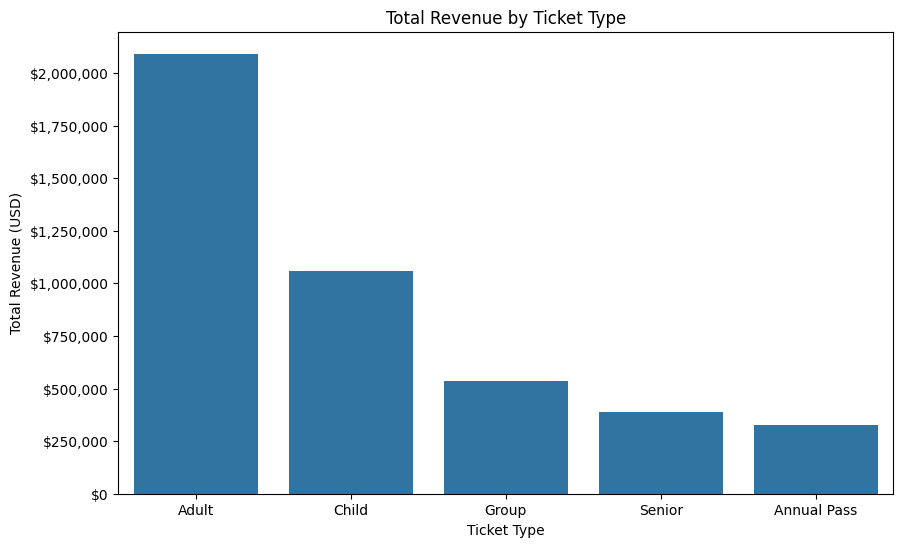

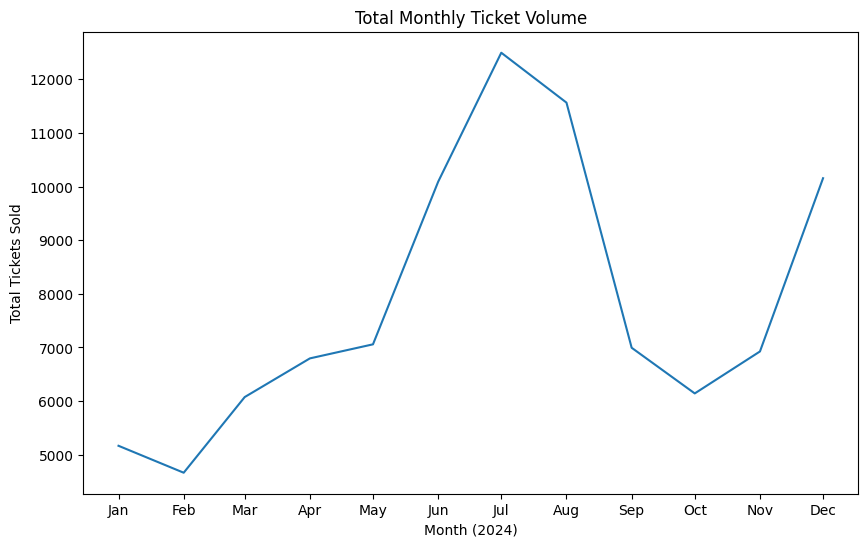

In [60]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: total revenue by ticket type (bar)
revenue_by_type = df.groupby('ticket_type')['revenue'].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=revenue_by_type.index, y=revenue_by_type.values, ax=ax)
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.set_title('Total Revenue by Ticket Type')
ax.set_xlabel('Ticket Type')
ax.set_ylabel('Total Revenue (USD)')
plt.show()

# Chart 2: total monthly ticket volume across the year (line)
fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(x=monthly_tickets.index, y=monthly_tickets.values, ax=ax)
ax.set_xticks(monthly_tickets.index)
ax.set_xticklabels(monthly_tickets.index.strftime('%b'))
ax.set_title('Total Monthly Ticket Volume')
ax.set_xlabel('Month (2024)')
ax.set_ylabel('Total Tickets Sold')
plt.show()


---
# 💼 Business Insights
*What did I discover?*

- Adult brings in **$2,091,650**, the most of the five types, and Adult plus Child make up **71.6%** of annual revenue.  
  (Adult가 $2,091,650으로 다섯 유형 중 가장 많고, Adult와 Child를 합치면 연간 매출의 71.6%)
- Annual Pass is the lowest at **$326,160**, which is **7.4%** of annual revenue.  
  (Annual Pass는 $326,160으로 가장 낮고 연간 매출의 7.4%)
- Ticket volume peaks in July (**12,494**) and has a second high in December (**10,155**). February is the low at **4,666**.  
  (판매량은 7월 12,494에서 최고, 12월 10,155에서 두 번째 높은 지점. 2월 4,666이 최저)  


---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Prepare for July (**12,494** tickets) and December (**10,155**), the two busiest stretches.  
   (티켓이 가장 많은 7월(12,494)과 12월(10,155)에 대비하기)
2. Look for ways to lift February (**4,666**) and October (**6,144**), the weakest months.  
   (가장 약한 2월(4,666)과 10월(6,144)을 끌어올릴 방법 찾기)
3. Protect Adult and Child sales, since together they are **71.6%** of annual revenue.  
   (Adult와 Child는 합쳐서 연간 매출의 71.6%이므로 이 매출을 지키기)  


---
# ❌ Mistakes
*What mistakes did I make today?*

- I used `sns.barplot` with the default estimator, so Chart 1 showed the monthly average instead of the total. It needed `estimator=sum` and `errorbar=None`.  
  (sns.barplot 기본값 그대로 써서 차트 1이 총합이 아니라 월평균이었음. estimator=sum과 errorbar=None이 필요했음)
- I passed the `monthly_tickets` Series as `data=` to `sns.lineplot` and got a `TypeError`. The months are the index, not a column.  
  (monthly_tickets Series를 sns.lineplot의 data=로 넘겨서 TypeError가 남. 월은 열이 아니라 인덱스)
- Q3 first showed a pie chart with no percentage table, so the question was not answered as numbers.  
  (Q3을 처음에는 퍼센트 표 없이 파이 차트로만 보여서 숫자로 답하지 못했음)  


---
# ✅ What I Learned
*Today's biggest lesson*

- `sns.barplot` and `sns.lineplot` average the values by default. Use `estimator=sum` and `errorbar=None` for totals.  
  (sns.barplot과 sns.lineplot은 기본이 평균. 총합은 estimator=sum, errorbar=None)
- A Series has no column names. Pass `x=series.index` and `y=series.values` instead of `data=`.  
  (Series에는 열 이름이 없음. data= 대신 x=series.index, y=series.values로 넘김)
- A share is the group total divided by the overall total, times 100. A sorted table plotted as is keeps the bars in the Q1 order.  
  (비중은 그룹 합계를 전체 합계로 나눠 100을 곱함. 정렬한 표를 그대로 그리면 막대가 Q1 순서로 나옴)  


---
# 🧠 Reflection

**What was difficult?**  
Making Chart 1 and Chart 2 show totals and not averages.  
(차트 1, 2가 평균이 아니라 총합을 보여주게 만드는 것)

**Why?**  
The seaborn plots aggregate rows by default, and the monthly total was a Series with the month in the index.  
(seaborn 차트가 기본으로 행을 평균 내고, 월별 합계는 월이 인덱스에 있는 Series였음)

**How did I solve it?**  
Plotted the sorted revenue totals in the bar chart, and passed the Series index and values to the line chart.  
(막대 차트는 정렬한 매출 합계를 그리고, 선 차트에는 Series의 인덱스와 값을 넘김)

**What would I do differently next time?**  
Compare the bar and line heights with the Q1 and Q2 tables before reading the chart.  
(차트를 읽기 전에 막대와 선의 높이를 Q1, Q2 표와 비교하기)


---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★☆☆☆  
Totals, shares, and the two charts are clear. The seaborn default of averaging still needs checking each time.  
(총합, 비중, 두 차트는 이해함. seaborn의 기본 평균은 매번 확인이 필요함)

**Confidence**  
★★★★★★☆☆☆☆  

**Difficulty**  
★★★★★☆☆☆☆☆  
The pandas totals were short. The seaborn defaults were the hard part.  
(pandas 합계는 짧았고, 어려운 부분은 seaborn 기본값이었음)


---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Practice Day 33 — groupby & pivot (Round 3/5)  
  (GroupBy와 Pivot 복습)  
